In [3]:
# 1. DOWNLOAD WESAD FIRST. Standard library only; no training runs in this cell.
# Select your own Python 3.11/3.12 Miniconda kernel, then run cells from top to bottom.
from pathlib import Path
import hashlib
import http.client
import json
import os
import shutil
import time
import urllib.error
import urllib.request
import zipfile

PROJECT_DIR = Path.home() / "code" / "pulse-usb"  # Change only if you moved the project.
DATA_DIR = PROJECT_DIR / "data" / "wesad"
DATASET_URL = "https://uni-siegen.sciebo.de/s/HGdUkoNlW1Ub0Gx/download"
# If the publisher changes its link, replace DATASET_URL with its new direct ZIP URL,
# or manually place the official archive at ARCHIVE. Never use a processed Kaggle CSV.
ARCHIVE = DATA_DIR / "WESAD.zip"
EXPECTED_SUBJECTS = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17]
DATA_DIR.mkdir(parents=True, exist_ok=True)

def find_subject_files(root):
    found = {}
    for sid in EXPECTED_SUBJECTS:
        matches = sorted(root.rglob(f"S{sid}.pkl"))
        if len(matches) > 1:
            raise RuntimeError(f"Duplicate S{sid}.pkl files under {root}; keep one dataset copy there.")
        if matches:
            found[sid] = matches[0]
    return found

def download_wesad(url, destination, attempts=4):
    """Resume interrupted transfers; reject HTML/error pages before writing them."""
    partial = destination.with_suffix(".zip.part")
    identity_file = destination.with_suffix(".download.json")
    for attempt in range(attempts):
        try:
            identity = json.loads(identity_file.read_text()) if identity_file.exists() else {}
            offset = partial.stat().st_size if partial.exists() else 0
            if identity.get("url") != url:
                offset = 0
            headers = {"User-Agent": "pulse-usb-course-project/1.0", "Accept-Encoding": "identity"}
            if offset:
                headers["Range"] = f"bytes={offset}-"
                validator = identity.get("etag") or identity.get("last_modified")
                if validator:
                    headers["If-Range"] = validator
            request = urllib.request.Request(url, headers=headers)
            try:
                response = urllib.request.urlopen(request, timeout=90)
            except urllib.error.HTTPError as exc:
                if exc.code == 416 and partial.exists() and zipfile.is_zipfile(partial):
                    partial.replace(destination)
                    return
                raise
            with response:
                if "text/html" in response.headers.get("Content-Type", "").lower():
                    raise ValueError("Publisher returned a web page instead of WESAD.zip.")
                if offset and response.status == 206:
                    if not response.headers.get("Content-Range", "").startswith(f"bytes {offset}-"):
                        raise ValueError("Server returned an inconsistent resume offset.")
                else:
                    offset = 0  # Range ignored / changed remote file: restart our partial archive.
                identity_file.write_text(json.dumps({
                    "url": url, "etag": response.headers.get("ETag"),
                    "last_modified": response.headers.get("Last-Modified"),
                }, indent=2))
                remaining = int(response.headers.get("Content-Length") or 0)
                total = offset + remaining if remaining else None
                prefix = response.read(1024 * 1024)
                if not offset and not prefix.startswith(b"PK"):
                    raise ValueError("Response is not a ZIP archive. Check the publisher download link.")
                downloaded, last_print = offset, 0.0
                with partial.open("ab" if offset else "wb") as handle:
                    while prefix:
                        handle.write(prefix)
                        downloaded += len(prefix)
                        if time.monotonic() - last_print > 2:
                            progress = f" / {total / 2**30:.2f} GiB" if total else ""
                            print(f"\rDownloaded {downloaded / 2**30:.2f} GiB{progress}", end="", flush=True)
                            last_print = time.monotonic()
                        prefix = response.read(1024 * 1024)
                if total and downloaded != total:
                    raise OSError(f"Incomplete download: {downloaded} of {total} bytes")
            if not zipfile.is_zipfile(partial):
                raise ValueError("Incomplete/corrupt ZIP; keep the partial file and rerun to resume.")
            partial.replace(destination)
            print("\nDownload complete.")
            return
        except (OSError, ValueError, urllib.error.URLError, http.client.IncompleteRead) as exc:
            if attempt == attempts - 1:
                raise RuntimeError(
                    f"WESAD download failed: {exc}\n"
                    f"Get the original ZIP from https://uni-siegen.sciebo.de/s/HGdUkoNlW1Ub0Gx "
                    f"and save it as {destination}, then rerun this cell."
                ) from exc
            print(f"\nTransfer interrupted ({exc}); retry {attempt + 2}/{attempts}.")
            time.sleep(2 ** attempt)

subject_files = find_subject_files(DATA_DIR)
if len(subject_files) == len(EXPECTED_SUBJECTS):
    print("All 15 extracted subject files already exist; download skipped.")
elif ARCHIVE.exists():
    if not zipfile.is_zipfile(ARCHIVE):
        raise RuntimeError(f"{ARCHIVE} is not a ZIP. Rename the corrupt file before retrying.")
    print(f"Using existing archive: {ARCHIVE}")
else:
    if shutil.disk_usage(DATA_DIR).free < 20 * 2**30:
        raise RuntimeError("Keep at least 20 GiB free for the archive, extracted pickles and results.")
    print("Downloading the original multimodal WESAD archive (several GB).")
    print("Dataset terms and citation: https://archive.ics.uci.edu/dataset/465/wesad+wearable+stress+and+affect+detection")
    download_wesad(DATASET_URL, ARCHIVE)
print("Dataset directory:", DATA_DIR)


All 15 extracted subject files already exist; download skipped.
Dataset directory: /home/shinichi/code/pulse-usb/data/wesad


# Stress model training 



In [1]:
# 2. INSTALL INTO THIS NOTEBOOK'S KERNEL (safe to rerun; no conda activation required).
import importlib
import importlib.metadata as metadata
import subprocess
import sys

if sys.version_info[:2] not in {(3, 11), (3, 12)}:
    raise RuntimeError("Select a Python 3.11 or 3.12 Miniconda kernel for these fixed dependency versions.")

PACKAGES = {
    "numpy": "2.1.3", "scipy": "1.14.1", "pandas": "2.2.3",
    "scikit-learn": "1.5.2", "matplotlib": "3.9.4", "tqdm": "4.67.1",
    "neurokit2": "0.2.12",
}
missing = []
already_imported_changed = []
for package, version in PACKAGES.items():
    try:
        installed = metadata.version(package)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(f"{package}=={version}")
        module_name = {"scikit-learn": "sklearn"}.get(package, package)
        if module_name in sys.modules:
            already_imported_changed.append(module_name)
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
# Preserve an existing compatible PyTorch installation in your chosen kernel.
try:
    torch_version = metadata.version("torch")
except metadata.PackageNotFoundError:
    torch_version = None
if torch_version is None:
    # Official PyTorch 2.7.1 CUDA 12.6 wheels; no torchvision/torchaudio needed.
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "torch==2.7.1",
        "--index-url", "https://download.pytorch.org/whl/cu126",
    ])
importlib.invalidate_caches()
if already_imported_changed:
    raise RuntimeError(
        f"Packages changed after import: {already_imported_changed}. Restart this kernel, "
        "then run from the top; the dataset download will be skipped."
    )
print("Kernel:", sys.executable)
print("Packages ready. Next cell checks CUDA and the NVIDIA driver.")


Kernel: /home/shinichi/miniconda3/envs/cv_env/bin/python
Packages ready. Next cell checks CUDA and the NVIDIA driver.


In [4]:
# 3. Fixed experiment, imports and reproducibility.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import math, pickle, platform, random
from collections import Counter
from datetime import datetime, timezone
import matplotlib.pyplot as plt
import neurokit2 as nk
import numpy as np
import pandas as pd
import scipy, sklearn, torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from IPython.display import display
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
REQUIRE_CUDA = True
if REQUIRE_CUDA and not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable in this kernel. Check nvidia-smi and your PyTorch build, then restart. Set REQUIRE_CUDA=False only for intentional CPU training.")
major, minor = [int(v) for v in torch.__version__.split(".")[:2]]
if major != 2 or minor < 5:
    raise RuntimeError("Use PyTorch >=2.5,<3 in this kernel.")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_BF16 = DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()
torch.set_num_threads(min(8, os.cpu_count() or 1))
CONFIG = {
    "seed": 343, "pipeline_version": "wesad-msptd-inception-v2", "target_fs": 30,
    "window_seconds": 60, "guard_seconds": 2, "stride_seconds": 5,
    "max_epochs": 150, "min_attempted_epochs": 50, "patience": 30,
    "batch_size": 32, "learning_rate": 0.0005, "weight_decay": 0.01, "dropout": 0.4,
    "label_smoothing": 0.02, "development_folds": 4,
    "development_subjects": [2,3,4,5,6,7,8,9,10,11,13,14], "test_subjects": [15,16,17],
    "prv_used_as_model_input": False, "evaluation_status": "exploratory_reuse_of_previous_test_subjects",
}
RUN_DIR = PROJECT_DIR / "artifacts" / "stress" / (datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ") + "_v2")
RUN_DIR.mkdir(parents=True, exist_ok=False)
RUN_STARTED = time.perf_counter()
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.use_deterministic_algorithms(True)
def save_json(path, value):
    path.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
seed_everything(CONFIG["seed"])
save_json(RUN_DIR / "config.json", CONFIG)
print("Device:", DEVICE, "BF16 training:", USE_BF16)
if DEVICE.type == "cuda": print(torch.cuda.get_device_name(0))
print("New output folder:", RUN_DIR)


Device: cuda BF16 training: True
NVIDIA GeForce RTX 4060 Laptop GPU
New output folder: /home/shinichi/code/pulse-usb/artifacts/stress/20261122T152429_753234Z_v2


## Reuse original data and define one shared runtime

Only wrist BVP reaches the classifier. ECG is read in a development-only diagnostic audit;
it is never a model input, label substitute, sample-weight rule, or test inclusion rule.
PRV quality is reported separately from eligibility for waveform classification. An accepted
waveform is not a validated pulse measurement. Raw frame gaps/clipping/motion are additionally
checked when the exported predictor is used on phone rows.

In [5]:
# 4. SELECTIVE EXTRACTION, CRC CHECKS DURING EXTRACTION, AND DATA PROVENANCE.
subject_files = find_subject_files(DATA_DIR)
if len(subject_files) != len(EXPECTED_SUBJECTS):
    if not ARCHIVE.exists():
        raise FileNotFoundError("Run the first download cell first.")
    with zipfile.ZipFile(ARCHIVE) as zf:
        members = {}
        for sid in EXPECTED_SUBJECTS:
            matches = [m for m in zf.infolist() if Path(m.filename).name == f"S{sid}.pkl"]
            if len(matches) != 1:
                raise RuntimeError(f"Expected exactly one S{sid}.pkl in the official ZIP; got {len(matches)}.")
            members[sid] = matches[0]
        needed = sum(m.file_size for sid, m in members.items() if sid not in subject_files)
        if shutil.disk_usage(DATA_DIR).free < needed + 2 * 2**30:
            raise RuntimeError(f"Extraction needs {needed / 2**30:.1f} GiB plus 2 GiB free.")
        for sid, member in tqdm(members.items(), desc="Extracting subjects"):
            if sid in subject_files:
                continue
            destination = DATA_DIR / "WESAD" / f"S{sid}" / f"S{sid}.pkl"
            destination.parent.mkdir(parents=True, exist_ok=True)
            partial = destination.with_suffix(".pkl.part")
            with zf.open(member) as source, partial.open("wb") as target:
                shutil.copyfileobj(source, target, length=1024 * 1024)
            if partial.stat().st_size != member.file_size:
                raise RuntimeError(f"Incomplete extraction for S{sid}")
            partial.replace(destination)
        for member in zf.infolist():
            basename = Path(member.filename).name
            if "readme" in basename.lower() and basename.lower().endswith((".pdf", ".txt")):
                destination = DATA_DIR / basename
                if not destination.exists():
                    with zf.open(member) as source, destination.open("wb") as target:
                        shutil.copyfileobj(source, target)
subject_files = find_subject_files(DATA_DIR)
assert sorted(subject_files) == EXPECTED_SUBJECTS

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

provenance = {
    "publisher_url": DATASET_URL, "archive_sha256": sha256_file(ARCHIVE) if ARCHIVE.exists() else None,
    "hash_note": "Local reproducibility hash; no publisher-signed checksum was supplied.",
    "subjects": {str(sid): {"path": str(path), "bytes": path.stat().st_size}
                 for sid, path in subject_files.items()},
}
save_json(RUN_DIR / "data_provenance.json", provenance)
print("All 15 subject files found. Readme files:", list(DATA_DIR.glob("*readme*")))


All 15 subject files found. Readme files: [PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S10_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S11_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S13_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S14_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S15_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S16_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S17_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S2_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S3_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S4_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S5_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S6_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S7_readme.txt'), PosixPath('/home/shinichi/code/pulse-usb/data/wesad/S

In [6]:
RUNTIME_SOURCE = r'''"""Research-derived PPG preparation; no classifier training in this module."""
from fractions import Fraction
from pathlib import Path
import json
import numpy as np
import neurokit2 as nk
from scipy.ndimage import median_filter
from scipy.signal import butter, detrend, resample_poly, sosfiltfilt, welch

TARGET_FS = 30
WINDOW_SECONDS = 60
GUARD_SECONDS = 2
INPUT_SECONDS = 64
PIPELINE_VERSION = "wesad-msptd-inception-v2"

class SignalRejected(ValueError):
    pass

def refine_peaks(y, peaks):
    positions = np.asarray(peaks, dtype=float).copy()
    for i, p in enumerate(peaks):
        if 0 < p < len(y) - 1:
            left, center, right = y[p - 1:p + 2]
            curvature = left - 2 * center + right
            if curvature < -1e-12:
                positions[i] += np.clip(0.5 * (left - right) / curvature, -0.5, 0.5)
    return positions

def pulse_shape_quality(y, positions):
    cycles = []
    for start, end in zip(positions[:-1], positions[1:]):
        if not 0.30 <= (end - start) / TARGET_FS <= 1.50:
            continue
        cycle = np.interp(np.linspace(start, end, 64, endpoint=False), np.arange(len(y)), y)
        if cycle.std() > 1e-8:
            cycles.append((cycle - cycle.mean()) / cycle.std())
    if len(cycles) < 20:
        return 0.0
    cycles = np.stack(cycles)
    template = np.median(cycles, axis=0)
    template -= template.mean()
    norm = np.linalg.norm(template)
    if norm < 1e-8:
        return 0.0
    similarity = cycles @ template / (np.linalg.norm(cycles, axis=1) * norm)
    return float(np.clip(np.median(similarity), -1, 1))

def assess_peaks(clean):
    """MSPTDfast v2: no synthetic beat insertion, deletion or interval interpolation."""
    result = nk.ppg_findpeaks(clean, sampling_rate=TARGET_FS, method="msptdfast")
    peaks = np.unique(np.asarray(result["PPG_Peaks"], dtype=int))
    peaks = peaks[(peaks >= TARGET_FS) & (peaks < len(clean) - TARGET_FS)]
    if len(peaks) < 25:
        raise SignalRejected("Too few detected pulses")
    positions = refine_peaks(clean, peaks)
    ibi = np.diff(positions) / TARGET_FS
    # Local, BOUNDED tolerance. The old unbounded 3.5*MAD rule admitted gross errors.
    local = median_filter(ibi, size=9, mode="nearest")
    tolerance = np.minimum(0.20 * local, 0.150)
    valid = (ibi >= 0.30) & (ibi <= 1.50) & (np.abs(ibi - local) <= tolerance)
    fraction = float(valid.mean())
    if valid.sum() < 25:
        raise SignalRejected("Too few reliable pulse intervals")
    pair_valid = valid[:-1] & valid[1:]
    if pair_valid.sum() < 20:
        raise SignalRejected("Too few originally adjacent reliable interval pairs")
    # Require observations throughout the window, not just one clean fragment.
    midpoint_seconds = (positions[:-1] + positions[1:]) / (2 * TARGET_FS)
    block_counts = [int(np.sum(valid & (midpoint_seconds >= b) & (midpoint_seconds < b + 10)))
                    for b in range(0, WINDOW_SECONDS, 10)]
    shape = pulse_shape_quality(clean, positions)
    score = fraction + 0.25 * shape
    return {"peaks": peaks, "positions": positions, "ibi": ibi, "valid": valid,
            "pair_valid": pair_valid, "valid_fraction": fraction, "shape": shape,
            "block_counts": block_counts, "score": score}

def prepare_window(raw, sampling_rate, return_beats=False):
    """64 seconds uniform RAW PPG -> 2x1800 waveform and diagnostics.

    Literature-based components with explicit project adaptations. A quality pass
    is not proof of physiological accuracy; independent ECG audit remains necessary.
    """
    raw = np.asarray(raw, dtype=np.float64)
    fs = float(sampling_rate)
    if raw.ndim != 1 or not np.isfinite(raw).all():
        raise SignalRejected("Expected a finite one-dimensional raw PPG signal")
    if not np.isfinite(fs) or not 25 <= fs <= 1000:
        raise SignalRejected("Measured acquisition rate must be at least 25 Hz")
    required = int(round(INPUT_SECONDS * fs))
    if len(raw) < required:
        raise SignalRejected(f"Need {INPUT_SECONDS} seconds of raw PPG")
    raw = raw[-required:]
    if np.std(raw) < 1e-8:
        raise SignalRejected("Flat PPG")
    ratio = Fraction(TARGET_FS / fs).limit_denominator(10000)
    uniform = resample_poly(raw, ratio.numerator, ratio.denominator)
    length = INPUT_SECONDS * TARGET_FS
    if len(uniform) < length - 1:
        raise SignalRejected("Insufficient resampled duration")
    if len(uniform) < length:
        uniform = np.pad(uniform, (0, length - len(uniform)), mode="edge")
    # Rashid et al. 2021 used a third-order 0.7–3.7 Hz Butterworth filter.
    # Our offline 64 s inference buffer uses zero-phase filtering and 2 s context.
    sos = butter(3, [0.7, 3.7], btype="bandpass", fs=TARGET_FS, output="sos")
    clean = sosfiltfilt(sos, detrend(uniform[:length]))[60:1860]
    if not np.isfinite(clean).all() or np.std(clean) < 1e-8:
        raise SignalRejected("Invalid filtered PPG")
    clean = (clean - np.mean(clean)) / np.std(clean)
    # Beat-derived descriptors are DIAGNOSTICS ONLY, never stress-model inputs.
    # Do not turn failed pulse timing into fabricated or imputed HRV measurements.
    candidates = []
    for sign in (1, -1):
        try:
            candidate = assess_peaks(sign * clean)
            candidates.append((candidate["score"], sign, candidate))
        except (SignalRejected, ValueError, IndexError, ZeroDivisionError):
            continue
    diagnostic = {"prv_valid": False, "prv_reason": "No reliable MSPTDfast beat sequence",
                  "pulse_count": None, "valid_intervals": None,
                  "rejected_interval_fraction": None, "template_correlation": None,
                  "mean_hr_bpm": None, "rmssd_ms": None, "sdnn_ms": None}
    if candidates:
        _, sign, beats = max(candidates, key=lambda value: value[0])
        clean *= sign
        failures = []
        if beats["valid_fraction"] < 0.85:
            failures.append("More than 15% locally inconsistent intervals")
        if min(beats["block_counts"]) < 4:
            failures.append("Reliable beats do not span all 10-second blocks")
        if beats["shape"] < 0.80:
            failures.append("Inconsistent pulse morphology")
        diagnostic.update(pulse_count=int(len(beats["peaks"])), valid_intervals=int(beats["valid"].sum()),
                          rejected_interval_fraction=1 - beats["valid_fraction"],
                          template_correlation=beats["shape"], prv_reason="; ".join(failures))
        if not failures:
            ibi_ms = beats["ibi"][beats["valid"]] * 1000
            changes_ms = np.diff(beats["ibi"])[beats["pair_valid"]] * 1000
            diagnostic.update(prv_valid=True, mean_hr_bpm=float(60000 / np.mean(ibi_ms)),
                              rmssd_ms=float(np.sqrt(np.mean(changes_ms ** 2))),
                              sdnn_ms=float(np.std(ibi_ms, ddof=1)))
            if return_beats:
                diagnostic["pulse_times_seconds"] = (beats["positions"] / TARGET_FS).tolist()
    # A derivative channel helps the CNN represent pulse upstroke; no ECG input.
    derivative = np.gradient(clean)
    derivative /= max(float(derivative.std()), 1e-8)
    waveform = np.clip(np.stack((clean, derivative)), -6, 6).astype(np.float32)
    return waveform, diagnostic

# Adapted single-network multi-scale residual architecture, inspired by InceptionTime.
# Not an exact reproduction of its ensemble or a claimed published stress accuracy.
import torch
from torch import nn

class InceptionBlock(nn.Module):
    def __init__(self, in_channels, width=16):
        super().__init__()
        self.bottleneck = nn.Conv1d(in_channels, 32, 1, bias=False)
        self.paths = nn.ModuleList([nn.Conv1d(32, width, k, padding=k // 2, bias=False)
                                    for k in (9, 19, 39)])
        self.pool_path = nn.Sequential(nn.MaxPool1d(3, stride=1, padding=1),
                                       nn.Conv1d(in_channels, width, 1, bias=False))
        self.norm = nn.GroupNorm(8, 4 * width)

    def forward(self, x):
        hidden = self.bottleneck(x)
        outputs = [path(hidden) for path in self.paths]
        outputs.append(self.pool_path(x))
        return torch.relu(self.norm(torch.cat(outputs, dim=1)))

class DeterministicAdaptiveMean1d(nn.Module):
    """Adaptive-average bins using slice/mean, avoiding CUDA atomic backward."""
    def __init__(self, output_size):
        super().__init__()
        self.output_size = output_size

    def forward(self, x):
        length = x.shape[-1]
        bins = []
        for i in range(self.output_size):
            start = (i * length) // self.output_size
            end = ((i + 1) * length + self.output_size - 1) // self.output_size
            bins.append(x[..., start:end].mean(dim=-1))
        return torch.stack(bins, dim=-1)

class StressNet(nn.Module):
    """One trainable model: waveform Inception blocks + learned frequency branch."""
    def __init__(self, dropout=0.4):
        super().__init__()
        self.blocks = nn.ModuleList([InceptionBlock(2 if i == 0 else 64) for i in range(6)])
        self.shortcuts = nn.ModuleList([
            nn.Sequential(nn.Conv1d(2, 64, 1, bias=False), nn.GroupNorm(8, 64)),
            nn.Sequential(nn.Conv1d(64, 64, 1, bias=False), nn.GroupNorm(8, 64)),
        ])
        self.frequency = nn.Sequential(
            nn.Conv1d(1, 16, 9, padding=4), nn.GroupNorm(4, 16), nn.GELU(),
            nn.AvgPool1d(2), nn.Conv1d(16, 32, 5, padding=2), nn.GroupNorm(8, 32), nn.GELU(),
            DeterministicAdaptiveMean1d(16), nn.Flatten(), nn.Linear(512, 64), nn.GELU())
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Sequential(nn.Linear(192, 96), nn.GELU(), nn.Dropout(dropout), nn.Linear(96, 1))

    def forward(self, waveform):
        x, residual = waveform, waveform
        for i, block in enumerate(self.blocks):
            x = block(x)
            if (i + 1) % 3 == 0:
                x = torch.relu(x + self.shortcuts[i // 3](residual))
                if i == 2:
                    x = nn.functional.avg_pool1d(x, 2)
                residual = x
        temporal = torch.cat((x.mean(dim=-1), x.std(dim=-1, unbiased=False)), dim=1)
        # FFT always float32: half-precision FFT at length 1800 is unsupported on CUDA.
        with torch.autocast(device_type=waveform.device.type, enabled=False):
            spectrum = torch.fft.rfft(waveform[:, 0].float(), dim=-1).abs().square()[:, 30:241]
            spectrum = torch.log1p(100 * spectrum / spectrum.sum(dim=-1, keepdim=True).clamp_min(1e-8))
        spectral = self.frequency(spectrum[:, None])
        return self.head(self.dropout(torch.cat((temporal, spectral), dim=1))).squeeze(1)

class StressPredictor:
    def __init__(self, bundle_dir, device="cpu"):
        self.bundle_dir = Path(bundle_dir)
        self.device = torch.device(device)
        self.config = json.loads((self.bundle_dir / "model_config.json").read_text())
        if self.config["pipeline_version"] != PIPELINE_VERSION:
            raise ValueError("Incompatible preprocessing/model version")
        if self.config["input_shape"] != [2, 1800] or self.config["prv_used_as_model_input"]:
            raise ValueError("Incompatible model input contract")
        self.model = StressNet(self.config["dropout"]).to(self.device)
        self.model.load_state_dict(torch.load(self.bundle_dir / "stress_model.pt", map_location=self.device, weights_only=True))
        self.model.eval()

    def predict_prepared(self, waveform):
        waveform = np.asarray(waveform, dtype=np.float32)
        if waveform.shape != (2, 1800) or not np.isfinite(waveform).all():
            raise SignalRejected("Expected a finite 2x1800 prepared waveform")
        with torch.inference_mode():
            logit = self.model(torch.as_tensor(waveform[None], device=self.device))
            score = float(torch.sigmoid(logit).cpu().item())
        return {"stress_score": score, "threshold": self.config["threshold"],
                "label": "elevated_stress_pattern" if score >= self.config["threshold"] else "baseline_pattern",
                "experimental": True, "phone_validation": "not established",
                "interpretation": "Uncalibrated WESAD class score; not stress severity or a diagnosis"}

    def predict_raw(self, raw, sampling_rate):
        wave, diagnostic = prepare_window(raw, sampling_rate)
        return {**self.predict_prepared(wave), "signal_diagnostics": diagnostic,
                "signal_caution": "Quality gates cannot establish that a periodic signal is physiological"}

    def predict_phone_rows(self, rows, channel):
        channels = {"red": (1, 4), "green": (2, 5), "blue": (3, 6)}
        if channel not in channels:
            raise SignalRejected("Keep one red/green/blue channel fixed for the recording")
        rows = np.asarray(rows, dtype=float)
        if rows.ndim != 2 or rows.shape[1] != 8 or not np.isfinite(rows).all():
            raise SignalRejected("Expected finite time/RGB/clipping/motion rows with 8 columns")
        if len(rows) < 2 or np.any(np.diff(rows[:, 0]) <= 0):
            raise SignalRejected("Capture timestamps must strictly increase")
        end = rows[-1, 0]
        if end - rows[0, 0] < INPUT_SECONDS:
            raise SignalRejected("Need 64 seconds of real raw samples")
        start = end - INPUT_SECONDS
        offset = max(0, np.searchsorted(rows[:, 0], start, side="right") - 1)
        recent = rows[offset:]
        dt = np.diff(recent[:, 0])
        fs = 1 / np.median(dt)
        if fs < 25 or dt.max() > .10 or dt.std() / dt.mean() > .20:
            raise SignalRejected("Low/irregular FPS or frame gaps")
        vi, ci = channels[channel]
        if (np.any((recent[:, 1:4] < 0) | (recent[:, 1:4] > 255)) or
            np.any((recent[:, 4:7] < 0) | (recent[:, 4:7] > 1))):
            raise SignalRejected("Invalid RGB or clipping data")
        if recent[:, ci].mean() > .15 or recent[:, vi].mean() < 10:
            raise SignalRejected("Clipped or dark recording")
        if np.percentile(recent[:, 7], 90) > .65:
            raise SignalRejected("Excessive phone motion")
        count = round(INPUT_SECONDS * fs)
        actual_fs = count / INPUT_SECONDS
        raw = np.interp(start + np.arange(count) / actual_fs, recent[:, 0], recent[:, vi])
        return self.predict_raw(raw, actual_fs)
'''
exec(compile(RUNTIME_SOURCE, "stress_runtime.py", "exec"), globals())
assert PIPELINE_VERSION == CONFIG["pipeline_version"]
print("Shared preprocessing and model definitions ready.")


Shared preprocessing and model definitions ready.


## Preprocessing with a versioned cache

Training is done at 30 Hz to reduce the 64 Hz wrist / approximately 30 FPS camera mismatch.
This does not recover missing camera timing or establish wrist-to-fingertip equivalence.
The waveform is filtered and normalized per window, without learning from other people.
The derivative is a second representation of the same optical signal. No training-wide
scaler is needed. The model learns the frequency representation internally from the PPG.

Windows are label-pure, including filter context. Cache keys include the exact shared source,
stride, and source-file identities. The new cache cannot accidentally reuse v1 features.
The 5 s windows overlap heavily: all windows from one person stay together in a fold.

In [7]:
# 6. Construct 60-second windows with 2-second context on each side.
def subject_windows(path, sid):
    with path.open("rb") as handle: record = pickle.load(handle, encoding="latin1")
    bvp = np.asarray(record["signal"]["wrist"]["BVP"], dtype=float).reshape(-1)
    labels = np.asarray(record["label"]).reshape(-1)
    del record
    if not np.isfinite(bvp).all() or not np.isfinite(labels).all():
        raise ValueError(f"S{sid}: non-finite source data")
    if not np.all(labels == labels.astype(int)) or abs(len(bvp)/64 - len(labels)/700) > 1:
        raise ValueError(f"S{sid}: invalid labels or synchronized duration mismatch")
    boundaries = np.r_[0, np.flatnonzero(np.diff(labels) != 0)+1, len(labels)]
    waves, rows, rejects = [], [], []
    for left, right in zip(boundaries[:-1], boundaries[1:]):
        label = int(labels[left])
        if label not in (1,2): continue
        first = math.ceil(left*64/700)
        last = min(math.floor(right*64/700), len(bvp))
        for start in range(first, last-4096+1, CONFIG["stride_seconds"]*64):
            row = {"subject": sid, "label": label-1, "context_start_seconds": start/64,
                   "window_start_seconds": start/64+2}
            try:
                wave, diagnostic = prepare_window(bvp[start:start+4096], 64)
            except SignalRejected as exc:
                rejects.append({**row, "reason": str(exc)}); continue
            waves.append(wave); rows.append({**row, **diagnostic})
    if not waves: raise RuntimeError(f"S{sid}: no usable waveform windows")
    return np.stack(waves), rows, rejects

fingerprint = RUNTIME_SOURCE + str(CONFIG["stride_seconds"]) + nk.__version__
fingerprint += json.dumps({str(s): [str(p), p.stat().st_size, p.stat().st_mtime_ns] for s,p in subject_files.items()}, sort_keys=True)
CACHE_PATH = DATA_DIR / ("prepared_v2_"+hashlib.sha256(fingerprint.encode()).hexdigest()[:16]+".npz")
preprocess_started = time.perf_counter()
if CACHE_PATH.exists():
    with np.load(CACHE_PATH, allow_pickle=False) as z:
        X_wave = z["waveform"].copy()
        rows = json.loads(str(z["metadata_json"].item()))
        rejects = json.loads(str(z["rejections_json"].item()))
    print("Loaded matching v2 cache:", CACHE_PATH)
else:
    waves, rows, rejects = [], [], []
    for sid in tqdm(EXPECTED_SUBJECTS, desc="MSPTDfast preprocessing"):
        w, r, bad = subject_windows(subject_files[sid], sid)
        waves.append(w); rows.extend(r); rejects.extend(bad)
        print(f"S{sid}: {len(r)} waveform windows, {sum(v['prv_valid'] for v in r)} with usable PRV")
    X_wave = np.concatenate(waves).astype(np.float32)
    np.savez_compressed(CACHE_PATH, waveform=X_wave, metadata_json=json.dumps(rows), rejections_json=json.dumps(rejects))
table = pd.DataFrame(rows)
rejected_table = pd.DataFrame(rejects, columns=["subject","label","context_start_seconds","window_start_seconds","reason"])
y = table.label.to_numpy(dtype=np.int64)
groups = table.subject.to_numpy(dtype=np.int64)
assert X_wave.shape == (len(y),2,1800) and np.isfinite(X_wave).all()
table.to_csv(RUN_DIR / "accepted_windows.csv", index=False)
rejected_table.to_csv(RUN_DIR / "rejected_windows.csv", index=False)
save_json(RUN_DIR / "cache_manifest.json", {"cache":str(CACHE_PATH),"seconds":time.perf_counter()-preprocess_started})
counts = pd.crosstab(table.subject,table.label).reindex(index=EXPECTED_SUBJECTS,columns=[0,1],fill_value=0)
display(counts.rename(columns={0:"baseline",1:"stress"}))
if (counts < 5).any().any(): raise RuntimeError("Too few waveform windows in a subject/class. Investigate source data; do not silently drop participants.")
coverage = table.groupby(["subject","label"]).agg(waveform_windows=("prv_valid","size"),prv_valid_windows=("prv_valid","sum"))
coverage["prv_valid_fraction"] = coverage.prv_valid_windows / coverage.waveform_windows
coverage.to_csv(RUN_DIR/"quality_coverage.csv")
display(coverage)
print("NOTE: waveform acceptance and trustworthy PRV are different. No PRV is used by the CNN.")
print("Waveform array:", X_wave.shape, "Preprocessing minutes:", round((time.perf_counter()-preprocess_started)/60,2))


MSPTDfast preprocessing:   0%|          | 0/15 [00:00<?, ?it/s]

S2: 327 waveform windows, 127 with usable PRV
S3: 332 waveform windows, 62 with usable PRV
S4: 334 waveform windows, 201 with usable PRV
S5: 344 waveform windows, 101 with usable PRV
S6: 342 waveform windows, 176 with usable PRV
S7: 341 waveform windows, 156 with usable PRV
S8: 343 waveform windows, 166 with usable PRV
S9: 341 waveform windows, 126 with usable PRV
S10: 357 waveform windows, 172 with usable PRV
S11: 348 waveform windows, 170 with usable PRV
S13: 344 waveform windows, 108 with usable PRV
S14: 347 waveform windows, 279 with usable PRV
S15: 348 waveform windows, 125 with usable PRV
S16: 346 waveform windows, 148 with usable PRV
S17: 356 waveform windows, 138 with usable PRV


label,baseline,stress
subject,,
2,216,111
3,216,116
4,219,115
5,227,117
6,224,118
7,225,116
8,221,122
9,224,117
10,224,133


waveform_windows  prv_valid_windows  prv_valid_fraction
subject label                                                         
2       0                   216                127            0.587963
        1                   111                  0            0.000000
3       0                   216                 62            0.287037
        1                   116                  0            0.000000
4       0                   219                201            0.917808
        1                   115                  0            0.000000
5       0                   227                101            0.444934
        1                   117                  0            0.000000
6       0                   224                176            0.785714
        1                   118                  0            0.000000
7       0                   225                156            0.693333
        1                   116                  0            0.000000
8       0                   221                166            0.751131
        1                   122                  0            0.000000
9       0                   224                 95            0.424107
        1                   117                 31            0.264957
10      0                   224                133            0.593750
        1                   133                 39            0.293233
11      0                   224                170            0.758929
        1                   124                  0            0.000000
13      0                   224                107            0.477679
        1                   120                  1            0.008333
14      0                   224                224            1.000000
        1                   123                 55            0.447154
15      0                   223                 93            0.417040
        1                   125                 32            0.256000
16      0                   224                 82            0.366071
        1                   122                 66            0.540984
17      0                   224                119            0.531250
        1                   132                 19            0.143939

NOTE: waveform acceptance and trustworthy PRV are different. No PRV is used by the CNN.
Waveform array: (5150, 2, 1800) Preprocessing minutes: 4.53


## ECG sanity audit on development recordings

This checks whether retained pulse timing resembles the simultaneous ECG. It does not
train the classifier, change quality thresholds, or use ECG from S15/S16/S17. ECG peaks
are automatically detected references rather than manually verified ground truth.
Invalid PRV remains missing, not zero. Both coverage and error matter: rejecting bad
timing should not be described as recovering it.

Development ECG audit:   0%|          | 0/12 [00:00<?, ?it/s]

,prv_valid,hr_abs_error,rmssd_abs_error
label,,,
0,0.635417,0.647693,17.499342
1,0.083333,0.874222,22.402879


Report this audit as a sampled sanity check, not full beat-detection validation.


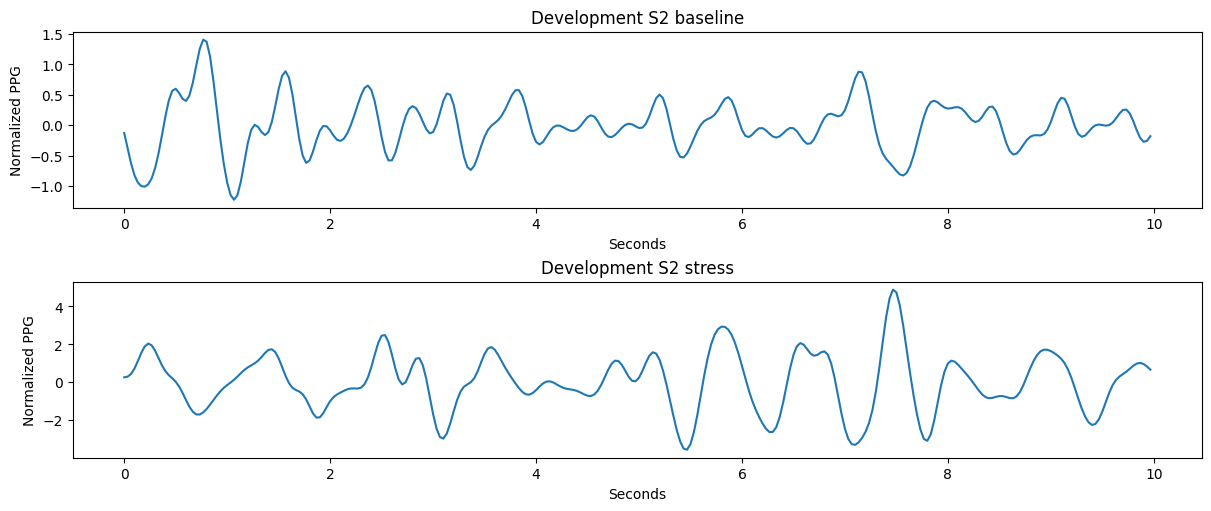

In [8]:
# 7. Audit a deterministic sample of development recordings only.
audit_rows = []
for sid in tqdm(CONFIG["development_subjects"], desc="Development ECG audit"):
    with subject_files[sid].open("rb") as handle: record = pickle.load(handle, encoding="latin1")
    bvp = np.asarray(record["signal"]["wrist"]["BVP"]).reshape(-1)
    ecg = np.asarray(record["signal"]["chest"]["ECG"]).reshape(-1)
    for label in (0,1):
        selection = table[(table.subject==sid)&(table.label==label)]
        positions = np.unique(np.linspace(0,len(selection)-1,min(8,len(selection)),dtype=int))
        for pos in positions:
            row = selection.iloc[pos]; start = float(row.context_start_seconds)
            base = {"subject":sid,"label":label,"start_seconds":start}
            try:
                _, d = prepare_window(bvp[round(start*64):round(start*64)+4096],64)
                segment = ecg[round((start+2)*700):round((start+2)*700)+42000]
                _, ref = nk.ecg_peaks(nk.ecg_clean(segment,sampling_rate=700),sampling_rate=700,correct_artifacts=False)
                ibi = np.diff(ref["ECG_R_Peaks"])/700
                if len(ibi)<20 or np.any(ibi<=0): raise ValueError("Insufficient ECG reference beats")
                reference_hr = float(60/ibi.mean())
                reference_rmssd = float(np.sqrt(np.mean(np.diff(ibi)**2))*1000)
                audit_rows.append({**base,"prv_valid":d["prv_valid"],"ppg_hr":d["mean_hr_bpm"],
                    "ecg_hr":reference_hr,"ppg_rmssd_ms":d["rmssd_ms"],"ecg_rmssd_ms":reference_rmssd,
                    "hr_abs_error":abs(d["mean_hr_bpm"]-reference_hr) if d["prv_valid"] else None,
                    "rmssd_abs_error":abs(d["rmssd_ms"]-reference_rmssd) if d["prv_valid"] else None,
                    "reason":d["prv_reason"]})
            except (ValueError,IndexError,ZeroDivisionError) as exc:
                audit_rows.append({**base,"audit_error":str(exc)})
    del record,bvp,ecg
audit = pd.DataFrame(audit_rows)
audit.to_csv(RUN_DIR/"development_ecg_audit.csv",index=False)
display(audit.groupby("label")[["prv_valid","hr_abs_error","rmssd_abs_error"]].mean())
print("Report this audit as a sampled sanity check, not full beat-detection validation.")
fig,axes=plt.subplots(2,1,figsize=(12,5),constrained_layout=True)
for label,ax in enumerate(axes):
    idx=np.flatnonzero((groups==2)&(y==label))[0]
    ax.plot(np.arange(300)/30,X_wave[idx,0,:300])
    ax.set(title=f"Development S2 {'baseline' if label==0 else 'stress'}",xlabel="Seconds",ylabel="Normalized PPG")
fig.savefig(RUN_DIR/"training_signal_examples.png",dpi=160);plt.show()


In [9]:
# 8. Four participant-grouped development folds. Keep the old test subjects separate.
dev_ids = np.array(CONFIG["development_subjects"])
test_ids = set(CONFIG["test_subjects"])
assert not set(dev_ids)&test_ids and set(dev_ids)|test_ids==set(EXPECTED_SUBJECTS)
development_idx = np.flatnonzero(np.isin(groups,dev_ids))
test_idx = np.flatnonzero(np.isin(groups,sorted(test_ids)))
shuffled = np.random.default_rng(CONFIG["seed"]).permutation(dev_ids)
fold_subjects = [part.tolist() for part in np.array_split(shuffled,CONFIG["development_folds"])]
save_json(RUN_DIR/"split_manifest.json",{"development_validation_folds":fold_subjects,
    "development_subjects":dev_ids.tolist(),"test_subjects":sorted(test_ids),
    "test_status":CONFIG["evaluation_status"],"window_split":False})
print("Development validation folds:",fold_subjects)
print("Exploratory test reuse:",sorted(test_ids))


Development validation folds: [[9, 8, 7], [10, 11, 14], [6, 4, 3], [5, 2, 13]]
Exploratory test reuse: [15, 16, 17]


## Train one architecture with four development fits

These fits assess the same model design on different people; the final app still loads
one refitted model. Validation chooses checkpoints by subject-mean macro-F1, with BCE
as a tie breaker. Training has a 150-epoch ceiling, waits at least 50 attempted epochs,
then can stop after 30 epochs without improvement. The selected checkpoint may be earlier.

The extra 5 s training views overlap. The CNN cannot see participant ID, labels, timing,
ECG, PRV quality flags, or PRV measurements as inputs. Augmentation changes gain, sign,
and small optical noise; it does not change pulse rhythm. Training weights balance
participant/class contributions. Validation/test scores are not reweighted to fake balance.
BF16 is used only for supported CUDA training; inference checks use float32.

In [10]:
# 9. Dataset, training and prediction helpers.
class WindowDataset(Dataset):
    def __init__(self,indices,augment=False):
        self.indices=np.asarray(indices);self.augment=augment
        counts=Counter((int(groups[i]),int(y[i])) for i in self.indices)
        weights=np.array([1/counts[(int(groups[i]),int(y[i]))] for i in self.indices])
        self.weights=(weights/weights.mean()).astype(np.float32)
    def __len__(self):return len(self.indices)
    def __getitem__(self,k):
        i=self.indices[k];wave=X_wave[i].copy()
        if self.augment:
            base=wave[0]*np.random.uniform(.85,1.15)*np.random.choice([-1,1])
            base+=np.random.normal(0,.02,base.shape).astype(np.float32)
            derivative=np.gradient(base);derivative/=max(float(derivative.std()),1e-8)
            wave=np.clip(np.stack((base,derivative)),-6,6).astype(np.float32)
        return torch.from_numpy(wave),torch.tensor(y[i],dtype=torch.float32),torch.tensor(self.weights[k])
def loader(indices,training=False,seed=343):
    return DataLoader(WindowDataset(indices,training),batch_size=CONFIG["batch_size"],shuffle=training,
        num_workers=0,pin_memory=DEVICE.type=="cuda",generator=torch.Generator().manual_seed(seed))
def cpu_state(model):return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
def train_epoch(model,batches,optimizer):
    model.train();total=0.;n=0
    for wave,labels,weights in batches:
        wave,labels,weights=wave.to(DEVICE),labels.to(DEVICE),weights.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.bfloat16,enabled=USE_BF16):
            logits=model(wave)
        target=labels*(1-CONFIG["label_smoothing"])+.5*CONFIG["label_smoothing"]
        losses=nn.functional.binary_cross_entropy_with_logits(logits.float(),target,reduction="none")
        loss=(losses*weights).mean()
        if not torch.isfinite(loss):raise RuntimeError("Non-finite loss; do not export these weights")
        loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0,error_if_nonfinite=True);optimizer.step()
        total+=float(loss.item())*len(labels);n+=len(labels)
    return total/n
def predict_indices(model,indices):
    model.eval();prob=[]
    with torch.inference_mode():
        for wave,_,_ in loader(indices):prob.append(torch.sigmoid(model(wave.to(DEVICE))).cpu().numpy())
    p=np.concatenate(prob)
    if not np.isfinite(p).all():raise RuntimeError("Non-finite model predictions")
    return p
def subject_scores(labels,p,subjects,threshold=.5):
    losses=[];f1s=[]
    p=np.clip(p.astype(float),1e-7,1-1e-7)
    for sid in np.unique(subjects):
        mask=subjects==sid
        losses.append(np.mean(-(labels[mask]*np.log(p[mask])+(1-labels[mask])*np.log(1-p[mask]))))
        f1s.append(f1_score(labels[mask],p[mask]>=threshold,average="macro",zero_division=0))
    return float(np.mean(losses)),float(np.mean(f1s))
probe=StressNet(CONFIG["dropout"])
print("Trainable parameters:",sum(p.numel() for p in probe.parameters()))
del probe

def check_training_backward():
    # Disposable random inputs; no dataset use or optimizer update.
    probe_model = StressNet(CONFIG["dropout"]).to(DEVICE)
    probe_wave = torch.randn(2, 2, 1800, device=DEVICE)
    with torch.autocast(device_type=DEVICE.type, dtype=torch.bfloat16, enabled=USE_BF16):
        probe_logits = probe_model(probe_wave)
    probe_target = torch.tensor([0.0, 1.0], device=DEVICE)
    probe_loss = nn.functional.binary_cross_entropy_with_logits(probe_logits.float(), probe_target)
    probe_loss.backward()
    for name, parameter in probe_model.named_parameters():
        if parameter.grad is None or not torch.isfinite(parameter.grad).all():
            raise RuntimeError(f"Backward preflight failed for {name}")
    print("Forward/backward preflight passed on", DEVICE, "with strict determinism.")

check_training_backward()


Trainable parameters: 280833
Forward/backward preflight passed on cuda with strict determinism.


In [11]:
# 10. Development training. No test predictions are made in this cell.
oof_probability=np.full(len(y),np.nan,dtype=float)
histories=[];fold_summaries=[]
for fold,validation_subjects in enumerate(fold_subjects,1):
    val_idx=np.flatnonzero(np.isin(groups,validation_subjects))
    train_idx=np.flatnonzero(np.isin(groups,dev_ids)&~np.isin(groups,validation_subjects))
    assert not set(groups[train_idx])&set(groups[val_idx])
    seed_everything(CONFIG["seed"]+fold)
    model=StressNet(CONFIG["dropout"]).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=CONFIG["learning_rate"],weight_decay=CONFIG["weight_decay"])
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=CONFIG["max_epochs"],eta_min=1e-5)
    batches=loader(train_idx,True,CONFIG["seed"]+fold)
    best_f1=-1.;best_loss=float("inf");best_epoch=0;best_state=None;stale=0;fold_history=[]
    started=time.perf_counter()
    for epoch in range(1,CONFIG["max_epochs"]+1):
        lr=optimizer.param_groups[0]["lr"]
        train_loss=train_epoch(model,batches,optimizer)
        probability=predict_indices(model,val_idx)
        val_loss,val_f1=subject_scores(y[val_idx],probability,groups[val_idx])
        item={"fold":fold,"epoch":epoch,"train_bce":train_loss,"validation_bce":val_loss,
              "validation_subject_macro_f1":val_f1,"learning_rate":lr}
        fold_history.append(item)
        improved=val_f1>best_f1+1e-4 or (abs(val_f1-best_f1)<=1e-4 and val_loss<best_loss-1e-5)
        if improved:
            best_f1,best_loss,best_epoch,best_state,stale=val_f1,val_loss,epoch,cpu_state(model),0
            torch.save(best_state,RUN_DIR/f"fold_{fold}_checkpoint.pt")
        else:stale+=1
        scheduler.step()
        pd.DataFrame(fold_history).to_csv(RUN_DIR/f"fold_{fold}_history.csv",index=False)
        if epoch==1 or epoch%5==0:print(f"Fold {fold} epoch {epoch:03d}: train={train_loss:.3f}, val={val_loss:.3f}, subject F1={val_f1:.3f}, best epoch={best_epoch}")
        if epoch>=CONFIG["min_attempted_epochs"] and stale>=CONFIG["patience"]:break
    if best_state is None:raise RuntimeError("No valid checkpoint")
    model.load_state_dict(best_state)
    oof_probability[val_idx]=predict_indices(model,val_idx)
    histories.extend(fold_history)
    fold_summaries.append({"fold":fold,"validation_subjects":validation_subjects,"selected_epoch":best_epoch,
        "attempted_epochs":len(fold_history),"selected_subject_macro_f1":best_f1,
        "selected_bce":best_loss,"seconds":time.perf_counter()-started})
    save_json(RUN_DIR/"development_fold_summaries.json",fold_summaries)
    print("Fold finished:",fold_summaries[-1])
    del model,optimizer,scheduler,batches,best_state
    if DEVICE.type=="cuda":torch.cuda.empty_cache()
assert np.isfinite(oof_probability[development_idx]).all()
pd.DataFrame(histories).to_csv(RUN_DIR/"development_training_history.csv",index=False)
development_predictions=table.iloc[development_idx][["subject","label","window_start_seconds"]].copy()
development_predictions["score"]=oof_probability[development_idx]
development_predictions.to_csv(RUN_DIR/"development_validation_predictions.csv",index=False)


Fold 1 epoch 001: train=0.528, val=0.422, subject F1=0.784, best epoch=1
Fold 1 epoch 005: train=0.143, val=0.754, subject F1=0.672, best epoch=4
Fold 1 epoch 010: train=0.088, val=0.401, subject F1=0.870, best epoch=4
Fold 1 epoch 015: train=0.094, val=0.318, subject F1=0.901, best epoch=15
Fold 1 epoch 020: train=0.067, val=0.387, subject F1=0.892, best epoch=19
Fold 1 epoch 025: train=0.063, val=0.377, subject F1=0.889, best epoch=19
Fold 1 epoch 030: train=0.061, val=0.371, subject F1=0.901, best epoch=19
Fold 1 epoch 035: train=0.059, val=0.354, subject F1=0.902, best epoch=19
Fold 1 epoch 040: train=0.062, val=0.389, subject F1=0.884, best epoch=19
Fold 1 epoch 045: train=0.058, val=0.362, subject F1=0.894, best epoch=19
Fold 1 epoch 050: train=0.058, val=0.356, subject F1=0.889, best epoch=19
Fold finished: {'fold': 1, 'validation_subjects': [9, 8, 7], 'selected_epoch': 19, 'attempted_epochs': 50, 'selected_subject_macro_f1': 0.9064421477898822, 'selected_bce': 0.303944642776759

The following development scores are used for selection. They are not an unbiased
new test estimate because fold checkpoints and the threshold use these validation labels.
No threshold is selected from S15/S16/S17. The exported score remains uncalibrated.

Locked decision threshold: 0.31000000000000005 Final duration: 14 epochs


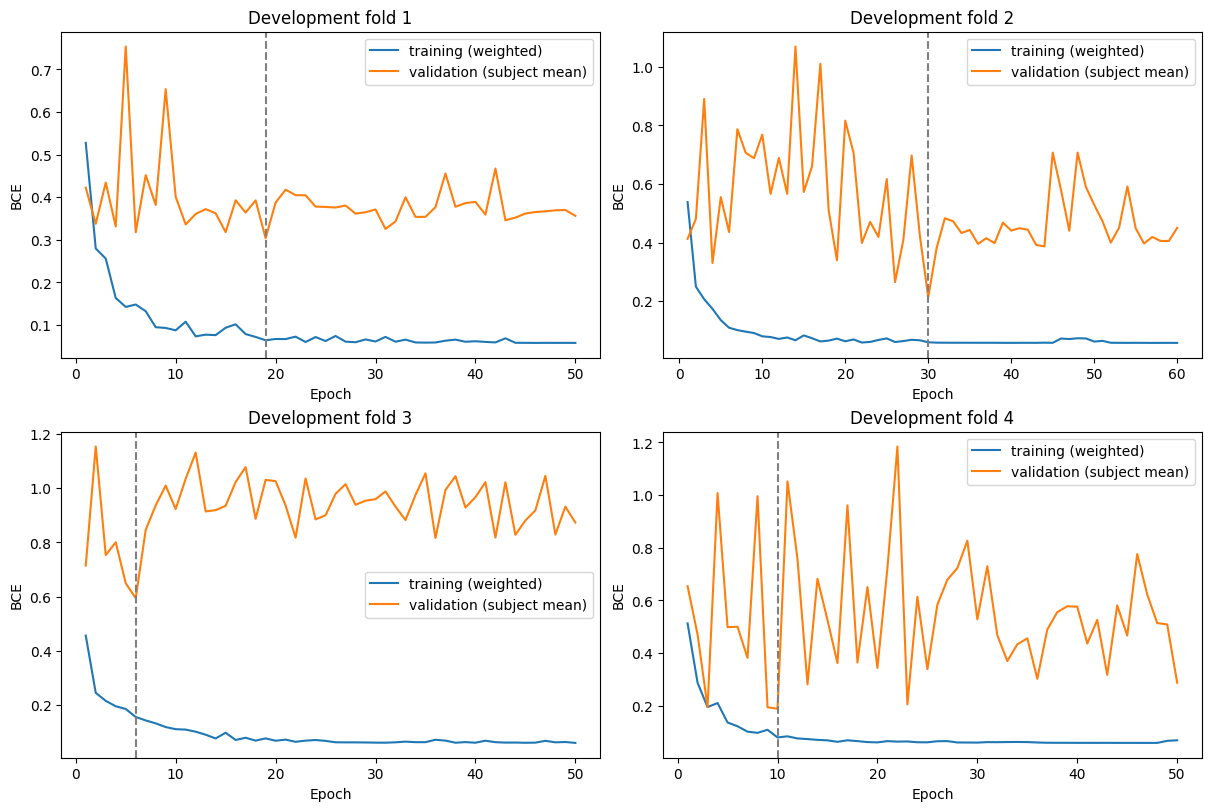

In [12]:
# 11. Pick threshold from development validation predictions, then lock final duration.
threshold_rows=[]
for threshold in np.linspace(.2,.8,61):
    _,score=subject_scores(y[development_idx],oof_probability[development_idx],groups[development_idx],threshold)
    threshold_rows.append({"threshold":float(threshold),"development_subject_macro_f1":score})
threshold_table=pd.DataFrame(threshold_rows)
best=max(threshold_rows,key=lambda r:(r["development_subject_macro_f1"],-abs(r["threshold"]-.5)))
THRESHOLD=best["threshold"]
FINAL_EPOCHS=max(1,int(round(np.median([r["selected_epoch"] for r in fold_summaries]))))
threshold_table.to_csv(RUN_DIR/"development_threshold_search.csv",index=False)
save_json(RUN_DIR/"selection_summary.json",{"threshold":THRESHOLD,"final_epochs":FINAL_EPOCHS,
    "development_subject_macro_f1_at_selected_threshold":best["development_subject_macro_f1"],
    "selection_only":True,"folds":fold_summaries})
print("Locked decision threshold:",THRESHOLD,"Final duration:",FINAL_EPOCHS,"epochs")
fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
history=pd.DataFrame(histories)
for fold,ax in enumerate(axes.flat,1):
    h=history[history.fold==fold]
    ax.plot(h.epoch,h.train_bce,label="training (weighted)")
    ax.plot(h.epoch,h.validation_bce,label="validation (subject mean)")
    ax.axvline(fold_summaries[fold-1]["selected_epoch"],linestyle="--",color="gray")
    ax.set(title=f"Development fold {fold}",xlabel="Epoch",ylabel="BCE");ax.legend()
fig.savefig(RUN_DIR/"training_curves.png",dpi=160);plt.show()


In [13]:
# 12. Refit ONE final model on all 12 development participants; no test-set monitoring.
seed_everything(CONFIG["seed"]+100)
final_model=StressNet(CONFIG["dropout"]).to(DEVICE)
optimizer=torch.optim.AdamW(final_model.parameters(),lr=CONFIG["learning_rate"],weight_decay=CONFIG["weight_decay"])
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=CONFIG["max_epochs"],eta_min=1e-5)
batches=loader(development_idx,True,CONFIG["seed"]+100)
final_history=[]
for epoch in range(1,FINAL_EPOCHS+1):
    loss=train_epoch(final_model,batches,optimizer);scheduler.step()
    final_history.append({"epoch":epoch,"train_bce":loss})
    pd.DataFrame(final_history).to_csv(RUN_DIR/"final_training_history.csv",index=False)
    torch.save(cpu_state(final_model),RUN_DIR/"final_checkpoint.pt")
    if epoch==1 or epoch%5==0 or epoch==FINAL_EPOCHS:print(f"Final fit {epoch}/{FINAL_EPOCHS}: BCE={loss:.4f}")
final_model.eval()


Final fit 1/14: BCE=0.5007
Final fit 5/14: BCE=0.1374
Final fit 10/14: BCE=0.0851
Final fit 14/14: BCE=0.0801


StressNet(
  (blocks): ModuleList(
    (0): InceptionBlock(
      (bottleneck): Conv1d(2, 32, kernel_size=(1,), stride=(1,), bias=False)
      (paths): ModuleList(
        (0): Conv1d(32, 16, kernel_size=(9,), stride=(1,), padding=(4,), bias=False)
        (1): Conv1d(32, 16, kernel_size=(19,), stride=(1,), padding=(9,), bias=False)
        (2): Conv1d(32, 16, kernel_size=(39,), stride=(1,), padding=(19,), bias=False)
      )
      (pool_path): Sequential(
        (0): MaxPool1d(kernel_size=3, stride=1, padding=1, dilation=1, ceil_mode=False)
        (1): Conv1d(2, 16, kernel_size=(1,), stride=(1,), bias=False)
      )
      (norm): GroupNorm(8, 64, eps=1e-05, affine=True)
    )
    (1-5): 5 x InceptionBlock(
      (bottleneck): Conv1d(64, 32, kernel_size=(1,), stride=(1,), bias=False)
      (paths): ModuleList(
        (0): Conv1d(32, 16, kernel_size=(9,), stride=(1,), padding=(4,), bias=False)
        (1): Conv1d(32, 16, kernel_size=(19,), stride=(1,), padding=(9,), bias=False)
     

## Exploratory evaluation on the previously inspected test people

These people remain outside model fitting, checkpoint selection and threshold selection.
Their previous results motivated this revision, so they cannot now establish independent
confirmation of a claimed improvement. We report them honestly with per-subject scores.
AUC is a ranking metric, not accuracy. Include the confusion matrix and stress precision;
high recall with many false stress alerts is not a strong final result.

In [14]:
# 13. Exploratory evaluation on the three previously inspected, fitting-excluded people.
test_probability = predict_indices(final_model, test_idx)
test_predicted = (test_probability >= THRESHOLD).astype(int)

def classification_metrics(labels, probabilities):
    predicted = (probabilities >= THRESHOLD).astype(int)
    return {
        "n_windows": int(len(labels)), "accuracy": float(accuracy_score(labels, predicted)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, predicted)),
        "macro_f1": float(f1_score(labels, predicted, average="macro", zero_division=0)),
        "stress_precision": float(precision_score(labels, predicted, zero_division=0)),
        "stress_recall": float(recall_score(labels, predicted, zero_division=0)),
        "roc_auc": float(roc_auc_score(labels, probabilities)),
        "average_precision": float(average_precision_score(labels, probabilities)),
        "brier_score": float(brier_score_loss(labels, probabilities)),
    }

test_metrics = classification_metrics(y[test_idx], test_probability)
test_metrics["evaluation_status"] = CONFIG["evaluation_status"]
per_subject = []
for sid in sorted(test_ids):
    mask = groups[test_idx] == sid
    per_subject.append({"subject": sid, **classification_metrics(y[test_idx][mask], test_probability[mask])})
subject_results = pd.DataFrame(per_subject)
subject_results.to_csv(RUN_DIR / "test_per_subject.csv", index=False)
test_metrics["subject_mean_macro_f1"] = float(subject_results.macro_f1.mean())
test_metrics["subject_mean_balanced_accuracy"] = float(subject_results.balanced_accuracy.mean())
test_metrics["threshold"] = THRESHOLD
test_metrics["test_subjects"] = sorted(test_ids)
save_json(RUN_DIR / "test_metrics.json", test_metrics)
predictions = table.iloc[test_idx].copy()
predictions["stress_score"] = test_probability
predictions["predicted_label"] = test_predicted
predictions.to_csv(RUN_DIR / "test_predictions.csv", index=False)
print(json.dumps(test_metrics, indent=2))
report = classification_report(y[test_idx], test_predicted, labels=[0, 1],
                               target_names=["baseline", "stress"], zero_division=0)
print(report)
(RUN_DIR / "classification_report.txt").write_text(report)
display(subject_results)


{
  "n_windows": 1050,
  "accuracy": 0.8352380952380952,
  "balanced_accuracy": 0.861902252771235,
  "macro_f1": 0.8317586660726739,
  "stress_precision": 0.698076923076923,
  "stress_recall": 0.9577836411609498,
  "roc_auc": 0.9064268272062728,
  "average_precision": 0.8103037210448003,
  "brier_score": 0.14089834624447203,
  "evaluation_status": "exploratory_reuse_of_previous_test_subjects",
  "subject_mean_macro_f1": 0.831829136167272,
  "subject_mean_balanced_accuracy": 0.8609990412654072,
  "threshold": 0.31000000000000005,
  "test_subjects": [
    15,
    16,
    17
  ]
}
              precision    recall  f1-score   support

    baseline       0.97      0.77      0.86       671
      stress       0.70      0.96      0.81       379

    accuracy                           0.84      1050
   macro avg       0.83      0.86      0.83      1050
weighted avg       0.87      0.84      0.84      1050



,subject,n_windows,accuracy,balanced_accuracy,macro_f1,stress_precision,stress_recall,roc_auc,average_precision,brier_score
0,15,348,0.686782,0.753848,0.686572,0.534483,0.992000,0.863570,0.690262,0.268785
1,16,346,0.936416,0.922900,0.929267,0.938596,0.877049,0.885429,0.905954,0.056197
2,17,356,0.882022,0.906250,0.879648,0.758621,1.000000,0.971253,0.935188,0.098208


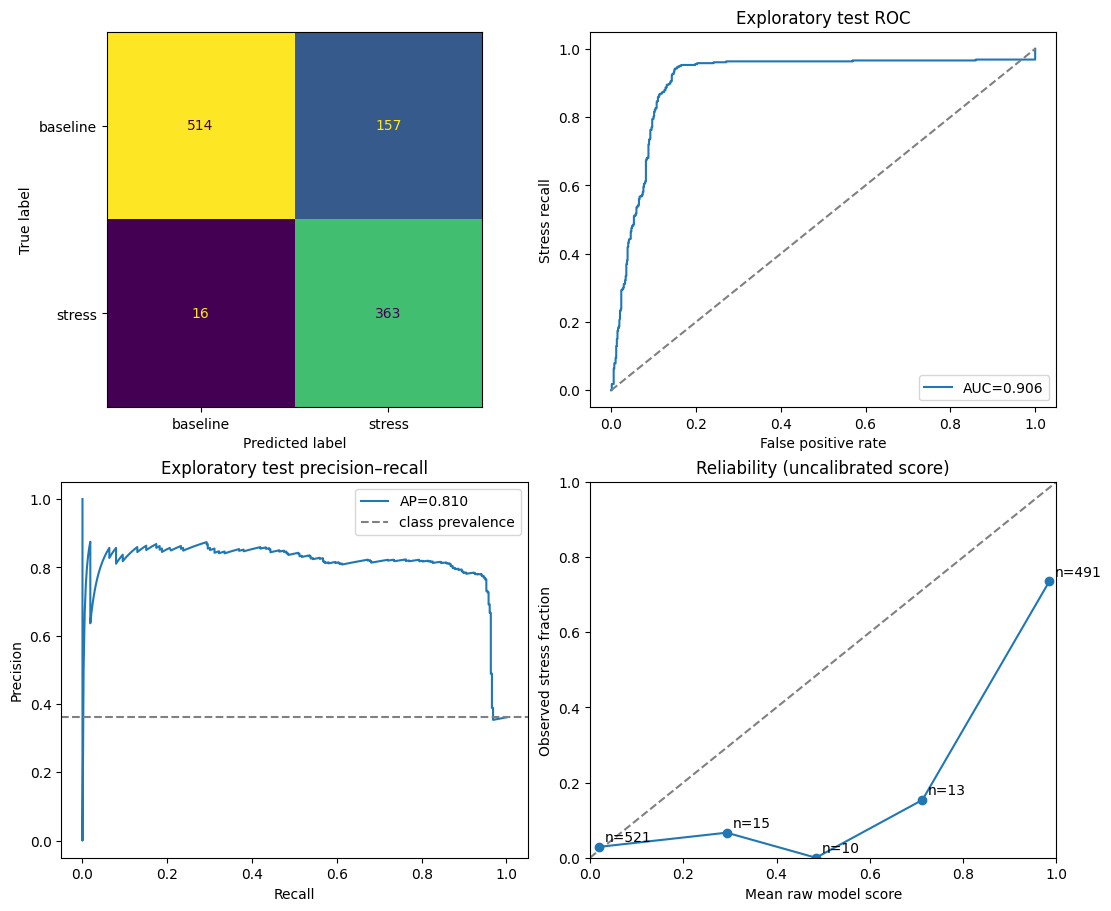

In [15]:
# 14. CONFUSION MATRIX, ROC, PRECISION–RECALL AND RAW-SCORE RELIABILITY PLOTS.
fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
ConfusionMatrixDisplay(confusion_matrix(y[test_idx], test_predicted, labels=[0, 1]),
                       display_labels=["baseline", "stress"]).plot(ax=axes[0, 0], colorbar=False)
fpr, tpr, _ = roc_curve(y[test_idx], test_probability)
axes[0, 1].plot(fpr, tpr, label=f"AUC={test_metrics['roc_auc']:.3f}")
axes[0, 1].plot([0, 1], [0, 1], "--", color="gray")
axes[0, 1].set(xlabel="False positive rate", ylabel="Stress recall", title="Exploratory test ROC")
axes[0, 1].legend()
precision, recall, _ = precision_recall_curve(y[test_idx], test_probability)
axes[1, 0].plot(recall, precision, label=f"AP={test_metrics['average_precision']:.3f}")
axes[1, 0].axhline(y[test_idx].mean(), linestyle="--", color="gray", label="class prevalence")
axes[1, 0].set(xlabel="Recall", ylabel="Precision", title="Exploratory test precision–recall")
axes[1, 0].legend()
bins = np.linspace(0, 1, 6)
bin_ids = np.minimum(np.digitize(test_probability, bins) - 1, 4)
mean_score, observed, bin_sizes = [], [], []
for k in range(5):
    mask = bin_ids == k
    if mask.any():
        mean_score.append(test_probability[mask].mean())
        observed.append(y[test_idx][mask].mean())
        bin_sizes.append(int(mask.sum()))
axes[1, 1].plot([0, 1], [0, 1], "--", color="gray")
axes[1, 1].plot(mean_score, observed, "o-")
axes[1, 1].set(xlabel="Mean raw model score", ylabel="Observed stress fraction",
               title="Reliability (uncalibrated score)", xlim=(0, 1), ylim=(0, 1))
for x, yy, count in zip(mean_score, observed, bin_sizes):
    axes[1, 1].annotate(f"n={count}", (x, yy), xytext=(4, 4), textcoords="offset points")
fig.savefig(RUN_DIR / "held_out_evaluation.png", dpi=180)
plt.show()


## Export and verify the complete model

The bundle contains the exact shared source, weights and threshold. V2 needs no PRV
feature scaler. The following checks reload the bundle and compare prepared/raw-input
predictions. Every failure should be investigated; do not report old v1 results as v2 output.

In [16]:
# 15. Export the one final model and the full runtime.
BUNDLE_DIR=RUN_DIR/"bundle";BUNDLE_DIR.mkdir(exist_ok=True)
torch.save(cpu_state(final_model),BUNDLE_DIR/"stress_model.pt")
(BUNDLE_DIR/"stress_runtime.py").write_text(RUNTIME_SOURCE,encoding="utf-8")
model_config={**CONFIG,"threshold":THRESHOLD,"final_epochs":FINAL_EPOCHS,"input_shape":[2,1800],
    "input_seconds_with_context":64,"architecture":"single six-block residual Inception + learned frequency branch",
    "fitted_subjects":dev_ids.tolist(),"test_subjects":sorted(test_ids),"score_calibrated":False,
    "phone_validation":"not established","prv_used_as_model_input":False}
save_json(BUNDLE_DIR/"model_config.json",model_config)
save_json(BUNDLE_DIR/"test_metrics.json",test_metrics)
versions={name:metadata.version(name) for name in [*PACKAGES,"torch"]}
save_json(RUN_DIR/"environment.json",{"packages":versions,"python":sys.version,"platform":platform.platform(),
    "device":str(DEVICE),"bf16_training":USE_BF16,"cuda_runtime":torch.version.cuda})
(BUNDLE_DIR/"requirements-training-freeze.txt").write_text("\n".join(f"{k}=={v}" for k,v in versions.items())+"\n")
(BUNDLE_DIR/"requirements-runtime.txt").write_text("numpy==2.1.3\nscipy==1.14.1\npandas==2.2.3\nneurokit2==0.2.12\ntorch>=2.5,<3\n")


73

In [17]:
# 16. Reload in a separate module and check float32 prediction parity.
import importlib.util
spec=importlib.util.spec_from_file_location("exported_stress_v2",BUNDLE_DIR/"stress_runtime.py")
module=importlib.util.module_from_spec(spec);sys.modules[spec.name]=module;spec.loader.exec_module(module)
reloaded=module.StressPredictor(BUNDLE_DIR,device="cpu")
indices=development_idx[:4]
expected=predict_indices(final_model,indices)
actual=np.array([reloaded.predict_prepared(X_wave[i])["stress_score"] for i in indices])
error=float(np.max(np.abs(expected-actual)))
assert error<1e-4,f"CPU/GPU export mismatch: {error}"
row=table.iloc[int(indices[0])];sid=int(row.subject);start=round(float(row.context_start_seconds)*64)
with subject_files[sid].open("rb") as handle:record=pickle.load(handle,encoding="latin1")
raw=np.asarray(record["signal"]["wrist"]["BVP"]).reshape(-1)[start:start+4096].copy();del record
raw_score=reloaded.predict_raw(raw,64)["stress_score"]
assert abs(raw_score-actual[0])<1e-5,"Raw/prepared preprocessing mismatch"
save_json(RUN_DIR/"export_verification.json",{"max_cpu_gpu_score_difference":error,"raw_prepared_difference":float(abs(raw_score-actual[0]))})
print("Export verified:",error)


Export verified: 1.1920928955078125e-06


In [18]:
# 17. Model card, reproducibility checksums, and portable inference ZIP.
card=f"""# Experimental PPG stress classifier — v2

Architecture: one six-block multi-scale residual CNN with a learned frequency branch.
Input: 64 seconds raw PPG; central 60 s at 30 Hz; normalized signal + derivative.
No PRV/HRV, ECG, EDA, temperature, subject ID, timestamps or quality flags are classifier inputs.
PRV is reported separately only if bounded interval and morphology checks pass.
MSPTDfast cannot recover physiological pulse information absent from a noisy signal.

Fitted subjects: {dev_ids.tolist()}. Four development folds selected checkpoints and threshold.
Final fit: {FINAL_EPOCHS} epochs. Decision threshold: {THRESHOLD:.2f}.
Test subjects excluded from fitting: {sorted(test_ids)}.
Evaluation status: {CONFIG['evaluation_status']}.
These same test people were inspected in v1; these results are exploratory, not independent confirmation.
Overlapping windows are correlated; window count is not participant count.

Accuracy: {test_metrics['accuracy']:.4f}
Macro-F1: {test_metrics['macro_f1']:.4f}
Subject-mean macro-F1: {test_metrics['subject_mean_macro_f1']:.4f}
Stress precision: {test_metrics['stress_precision']:.4f}
Stress recall: {test_metrics['stress_recall']:.4f}
ROC-AUC: {test_metrics['roc_auc']:.4f}

The sigmoid output is an uncalibrated baseline/stress class score, not a personal stress
probability, severity measurement or disease diagnosis. WESAD is a wrist-sensor lab
dataset. Its stress protocol includes movement; waveform classifiers can learn motion
or protocol artifacts. Corrected PRV gating removes corrupted PRV inputs but does not
prove removal of all waveform confounds. Phone fingertip transfer is not established.
Independent labelled phone recordings and new participants are required for validation.

The live app retains only 24 seconds. Integration needs a real 64-second raw buffer,
stable channel/exposure, frame timestamps and capture-quality checks. Do not repeat or
pad a 24-second report to pretend it contains 64 seconds. Live app code is unchanged.

Load: import StressPredictor from stress_runtime, then predict_raw(raw, actual_fs),
or predict_phone_rows(rows, channel='green'). Keep the entire bundle together.
SignalRejected means insufficient/invalid acquisition. PRV can be unavailable even when
a waveform classifier score is returned; that score must remain marked experimental.

Research adaptations, not exact reproduced benchmarks or pretrained weights:
Charlton et al. (2025), doi:10.1088/1361-6579/adb89e (MSPTDfast);
Rashid et al. (2021), doi:10.1109/EMBC46164.2021.9630576 (PPG stress hybrid CNN);
Fawaz et al. (2020), doi:10.1007/s10618-020-00710-y (InceptionTime).
Dataset: WESAD, doi:10.24432/C57K5T. Follow the publisher's readme and cite its paper.
"""
(BUNDLE_DIR/"MODEL_CARD.md").write_text(card,encoding="utf-8")
(RUN_DIR/"SUBMISSION_SUMMARY.md").write_text(card,encoding="utf-8")
save_json(BUNDLE_DIR/"checksums.json",{p.name:sha256_file(p) for p in BUNDLE_DIR.iterdir() if p.is_file() and p.name!="checksums.json"})
shutil.make_archive(str(RUN_DIR/"stress_inference_bundle"),"zip",root_dir=BUNDLE_DIR)
print("Finished. Total minutes after setup:",round((time.perf_counter()-RUN_STARTED)/60,1))
print("Final bundle:",BUNDLE_DIR)
print("Submission summary:",RUN_DIR/"SUBMISSION_SUMMARY.md")
print("Development ECG audit:",RUN_DIR/"development_ecg_audit.csv")


Finished. Total minutes after setup: 26.1
Final bundle: /home/shinichi/code/pulse-usb/artifacts/stress/20261122T152429_753234Z_v2/bundle
Submission summary: /home/shinichi/code/pulse-usb/artifacts/stress/20261122T152429_753234Z_v2/SUBMISSION_SUMMARY.md
Development ECG audit: /home/shinichi/code/pulse-usb/artifacts/stress/20261122T152429_753234Z_v2/development_ecg_audit.csv
